# **Name : Prajwal C**

## Problem 1: Automatic Dictionary Construction for Named Entity Recognition (NER)

**Dataset:** CoNLL-2003

Develop a Python program to automatically construct three entity dictionaries (PERSON, LOCATION and ORGANIZATION) from the annotated training dataset. Use these dictionaries to identify entities in 200 unseen test sentences.

**Tasks:**
1. Extract annotated entity phrases.
2. Create unique dictionaries for each entity type.
3. Apply longest-phrase matching.
4. Calculate entity-level precision, recall and F1-score.

**Expected Output:** Dictionary sizes, predicted entities, correctly identified entities and evaluation scores.

In [1]:
!pip install -q datasets pandas matplotlib

In [3]:
!pip install -q -U datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 12.6 MB/s eta 0:00:00


In [5]:
from datasets import load_dataset


dataset = load_dataset(
    "lhoestq/conll2003",
    trust_remote_code=False
)

train_data = dataset["train"]
test_data = dataset["test"]

print("Training sentences:", len(train_data))
print("Test sentences:", len(test_data))
print("\nFirst training example:")
print(train_data[0])

dataset_infos.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  281kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

Training sentences: 14041
Test sentences: 3453

First training example:
{'id': '0', 'tokens': ['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.'], 'pos_tags': [22, 42, 16, 21, 35, 37, 16, 21, 7], 'chunk_tags': [11, 21, 11, 12, 21, 22, 11, 12, 0], 'ner_tags': [3, 0, 7, 0, 0, 0, 7, 0, 0]}


In [7]:

print(train_data.features["ner_tags"])

List(Value('int64'))


In [8]:

ner_feature = train_data.features["ner_tags"]

if hasattr(ner_feature, "feature") and hasattr(ner_feature.feature, "names"):
    label_names = ner_feature.feature.names
elif hasattr(ner_feature, "names"):
    label_names = ner_feature.names
else:
    label_names = [
        "O", "B-PER", "I-PER",
        "B-ORG", "I-ORG",
        "B-LOC", "I-LOC",
        "B-MISC", "I-MISC"
    ]

print("NER Labels:")
print(label_names)

NER Labels:
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


In [9]:

entity_types = {
    "PER": "PERSON",
    "LOC": "LOCATION",
    "ORG": "ORGANIZATION"
}


entity_dictionaries = {
    "PERSON": set(),
    "LOCATION": set(),
    "ORGANIZATION": set()
}



def extract_entities(tokens, ner_tags):
    entities = []
    current_tokens = []
    current_type = None

    for token, tag_id in zip(tokens, ner_tags):
        tag = label_names[int(tag_id)]

        if tag.startswith("B-"):
            if current_tokens and current_type:
                entities.append(
                    (current_type, tuple(current_tokens))
                )

            current_type = entity_types.get(tag[2:])
            current_tokens = [token] if current_type else []

        elif tag.startswith("I-"):
            new_type = entity_types.get(tag[2:])

            if current_type == new_type and current_tokens:
                current_tokens.append(token)
            else:
                if current_tokens and current_type:
                    entities.append(
                        (current_type, tuple(current_tokens))
                    )

                current_type = new_type
                current_tokens = [token] if new_type else []

        else:
            if current_tokens and current_type:
                entities.append(
                    (current_type, tuple(current_tokens))
                )

            current_tokens = []
            current_type = None

    if current_tokens and current_type:
        entities.append((current_type, tuple(current_tokens)))

    return entities



for example in train_data:
    entities = extract_entities(
        example["tokens"],
        example["ner_tags"]
    )

    for entity_type, phrase in entities:
        entity_dictionaries[entity_type].add(phrase)



for entity_type, phrases in entity_dictionaries.items():
    print(f"{entity_type}: {len(phrases)} unique phrases")

PERSON: 3614 unique phrases
LOCATION: 1332 unique phrases
ORGANIZATION: 2403 unique phrases


In [10]:

phrase_index = {}

for entity_type, phrases in entity_dictionaries.items():
    for phrase in phrases:
        phrase_index.setdefault(phrase, set()).add(entity_type)


def longest_phrase_matching(tokens):
    predictions = []
    i = 0


    max_length = max(
        (len(phrase) for phrase in phrase_index),
        default=0
    )

    while i < len(tokens):
        match = None

        for length in range(
            min(max_length, len(tokens) - i), 0, -1
        ):
            phrase = tuple(tokens[i:i + length])

            if phrase in phrase_index:
                entity_type = sorted(phrase_index[phrase])[0]
                match = {
                    "start": i,
                    "end": i + length,
                    "type": entity_type,
                    "text": " ".join(phrase)
                }
                break

        if match:
            predictions.append(match)
            i = match["end"]
        else:
            i += 1

    return predictions



test_examples = test_data.select(
    range(min(200, len(test_data)))
)


all_predictions = []

for sentence_id, example in enumerate(test_examples):
    predicted = longest_phrase_matching(example["tokens"])

    for entity in predicted:
        all_predictions.append({
            "Sentence ID": sentence_id + 1,
            "Sentence": " ".join(example["tokens"]),
            "Entity": entity["text"],
            "Entity Type": entity["type"],
            "Start": entity["start"],
            "End": entity["end"]
        })

predictions_df = pd.DataFrame(all_predictions)

print("Test sentences processed:", len(test_examples))
print("Total predicted entities:", len(predictions_df))

display(predictions_df.head(20))

Test sentences processed: 200
Total predicted entities: 204


,Sentence ID,Sentence,Entity,Entity Type,Start,End
0,3,"AL-AIN , United Arab Emirates 1996-12-06",United Arab Emirates,LOCATION,2,5
1,4,Japan began the defence of their Asian Cup tit...,Japan,LOCATION,0,1
2,4,Japan began the defence of their Asian Cup tit...,Syria,LOCATION,15,16
3,5,But China saw their luck desert them in the se...,China,LOCATION,1,2
4,6,China controlled most of the match and saw sev...,China,LOCATION,0,1
5,8,The former Soviet republic was playing in an A...,The,LOCATION,0,1
6,10,Two goals from defensive errors in the last si...,Japan,LOCATION,11,12
7,10,Two goals from defensive errors in the last si...,Syria,LOCATION,26,27
8,12,It was the second costly blunder by Syria in f...,Syria,LOCATION,7,8
9,14,Nader Jokhadar had given Syria the lead with a...,Syria,LOCATION,4,5


In [11]:


true_positive = 0
false_positive = 0
false_negative = 0
correct_entities = []

for sentence_id, example in enumerate(test_examples):

    tokens = example["tokens"]


    actual_entities = extract_entities(
        tokens, example["ner_tags"]
    )

    actual_set = set()

    for entity_type, phrase in actual_entities:

        phrase_length = len(phrase)

        for start in range(len(tokens) - phrase_length + 1):
            if tuple(tokens[start:start + phrase_length]) == phrase:
                actual_set.add(
                    (start, start + phrase_length, entity_type)
                )
                break


    predicted = longest_phrase_matching(tokens)

    predicted_set = {
        (entity["start"], entity["end"], entity["type"])
        for entity in predicted
    }


    matched = actual_set & predicted_set

    true_positive += len(matched)
    false_positive += len(predicted_set - actual_set)
    false_negative += len(actual_set - predicted_set)

    for start, end, entity_type in matched:
        correct_entities.append({
            "Sentence ID": sentence_id + 1,
            "Entity": " ".join(tokens[start:end]),
            "Entity Type": entity_type
        })



precision = (
    true_positive / (true_positive + false_positive)
    if true_positive + false_positive else 0
)

recall = (
    true_positive / (true_positive + false_negative)
    if true_positive + false_negative else 0
)

f1_score = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)



results = pd.DataFrame([{
    "Test Sentences": len(test_examples),
    "Correct Entities (TP)": true_positive,
    "False Positives (FP)": false_positive,
    "False Negatives (FN)": false_negative,
    "Precision": round(precision, 4),
    "Recall": round(recall, 4),
    "F1-Score": round(f1_score, 4)
}])

display(results)

print("\nCorrectly Identified Entities:")
display(pd.DataFrame(correct_entities).head(20))

,Test Sentences,Correct Entities (TP),False Positives (FP),False Negatives (FN),Precision,Recall,F1-Score
0,200,157,47,215,0.7696,0.422,0.5451



Correctly Identified Entities:


,Sentence ID,Entity,Entity Type
0,3,United Arab Emirates,LOCATION
1,4,Syria,LOCATION
2,4,Japan,LOCATION
3,5,China,LOCATION
4,6,China,LOCATION
5,10,Japan,LOCATION
6,10,Syria,LOCATION
7,12,Syria,LOCATION
8,14,Syria,LOCATION
9,15,Japan,LOCATION


## Problem 2: Case-Sensitive vs. Case-Insensitive Named Entity Recognition

**Dataset:** CoNLL-2003

Write a Python program to investigate how capitalization affects dictionary-based named entity recognition.

### Tasks
1. Construct entity dictionaries from the training dataset.
2. Perform case-sensitive and case-insensitive matching on the same test sentences.
3. Compare the number of entities detected.
4. Calculate precision and recall for both approaches.
5. Identify at least five incorrect predictions.

### Expected Output
A comparative table showing the performance of both methods, along with examples of incorrect predictions.

In [12]:


sensitive_index = defaultdict(set)
insensitive_index = defaultdict(set)

for entity_type, phrases in entity_dictionaries.items():
    for phrase in phrases:
        sensitive_index[phrase].add(entity_type)

        normalized_phrase = tuple(
            token.casefold() for token in phrase
        )
        insensitive_index[normalized_phrase].add(entity_type)



def match_entities(tokens, phrase_index, ignore_case=False):
    comparison_tokens = (
        [token.casefold() for token in tokens]
        if ignore_case else tokens
    )

    predictions = []
    max_length = max(
        (len(phrase) for phrase in phrase_index),
        default=0
    )

    i = 0

    while i < len(tokens):
        match = None

        for length in range(
            min(max_length, len(tokens) - i), 0, -1
        ):
            phrase = tuple(comparison_tokens[i:i + length])

            if phrase in phrase_index:
                entity_type = sorted(phrase_index[phrase])[0]

                match = {
                    "start": i,
                    "end": i + length,
                    "type": entity_type,
                    "text": " ".join(tokens[i:i + length])
                }
                break

        if match:
            predictions.append(match)
            i = match["end"]
        else:
            i += 1

    return predictions


print("Both matching methods are ready.")

Both matching methods are ready.


In [13]:
sensitive_predictions = []
insensitive_predictions = []

for sentence_id, example in enumerate(test_examples):

    tokens = example["tokens"]


    pred_sensitive = match_entities(
        tokens,
        sensitive_index,
        ignore_case=False
    )


    pred_insensitive = match_entities(
        tokens,
        insensitive_index,
        ignore_case=True
    )

    for entity in pred_sensitive:
        sensitive_predictions.append({
            "Sentence ID": sentence_id + 1,
            "Entity": entity["text"],
            "Type": entity["type"]
        })

    for entity in pred_insensitive:
        insensitive_predictions.append({
            "Sentence ID": sentence_id + 1,
            "Entity": entity["text"],
            "Type": entity["type"]
        })


print("Case-sensitive entities detected:",
      len(sensitive_predictions))

print("Case-insensitive entities detected:",
      len(insensitive_predictions))

print("\nCase-sensitive sample:")
display(pd.DataFrame(sensitive_predictions).head(10))

print("\nCase-insensitive sample:")
display(pd.DataFrame(insensitive_predictions).head(10))

Case-sensitive entities detected: 204
Case-insensitive entities detected: 321

Case-sensitive sample:


,Sentence ID,Entity,Type
0,3,United Arab Emirates,LOCATION
1,4,Japan,LOCATION
2,4,Syria,LOCATION
3,5,China,LOCATION
4,6,China,LOCATION
5,8,The,LOCATION
6,10,Japan,LOCATION
7,10,Syria,LOCATION
8,12,Syria,LOCATION
9,14,Syria,LOCATION



Case-insensitive sample:


,Sentence ID,Entity,Type
0,1,JAPAN,LOCATION
1,1,CHINA,LOCATION
2,3,United Arab Emirates,LOCATION
3,4,Japan,LOCATION
4,4,the,LOCATION
5,4,defence,ORGANIZATION
6,4,Syria,LOCATION
7,5,China,LOCATION
8,5,the,LOCATION
9,5,the,LOCATION


In [14]:
def gold_entity_set(tokens, ner_tags):
    """Extract exact gold entity spans directly from BIO tags."""
    result = set()
    start = None
    current_type = None

    for i, tag_id in enumerate(ner_tags):
        tag = label_names[int(tag_id)]

        if tag == "O":
            if start is not None and current_type:
                result.add((start, i, current_type))
            start, current_type = None, None
            continue

        prefix, raw_type = tag.split("-", 1)
        entity_type = entity_types.get(raw_type)

        if prefix == "B" or start is None or entity_type != current_type:
            if start is not None and current_type:
                result.add((start, i, current_type))

            start = i if entity_type else None
            current_type = entity_type

    if start is not None and current_type:
        result.add((start, len(tokens), current_type))

    return result


def evaluate_method(ignore_case):
    tp = fp = fn = 0
    errors = []

    phrase_index = insensitive_index if ignore_case else sensitive_index

    for sentence_id, example in enumerate(test_examples):
        tokens = example["tokens"]

        gold = gold_entity_set(tokens, example["ner_tags"])

        predicted_entities = match_entities(
            tokens, phrase_index, ignore_case=ignore_case
        )

        predicted = {
            (e["start"], e["end"], e["type"])
            for e in predicted_entities
        }

        correct = gold & predicted
        false_pos = predicted - gold
        false_neg = gold - predicted

        tp += len(correct)
        fp += len(false_pos)
        fn += len(false_neg)

        for start, end, entity_type in false_pos:
            errors.append({
                "Method": "Case-insensitive" if ignore_case else "Case-sensitive",
                "Sentence ID": sentence_id + 1,
                "Error": "False positive",
                "Entity": " ".join(tokens[start:end]),
                "Type": entity_type,
                "Sentence": " ".join(tokens)
            })

        for start, end, entity_type in false_neg:
            errors.append({
                "Method": "Case-insensitive" if ignore_case else "Case-sensitive",
                "Sentence ID": sentence_id + 1,
                "Error": "False negative",
                "Entity": " ".join(tokens[start:end]),
                "Type": entity_type,
                "Sentence": " ".join(tokens)
            })

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "Entities detected": tp + fp,
        "Correct entities": tp,
        "False positives": fp,
        "False negatives": fn,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }, errors


sensitive_metrics, sensitive_errors = evaluate_method(False)
insensitive_metrics, insensitive_errors = evaluate_method(True)

comparison = pd.DataFrame([
    {"Method": "Case-sensitive", **sensitive_metrics},
    {"Method": "Case-insensitive", **insensitive_metrics}
])

for column in ["Precision", "Recall", "F1-score"]:
    comparison[column] = comparison[column].round(4)

display(comparison)

,Method,Entities detected,Correct entities,False positives,False negatives,Precision,Recall,F1-score
0,Case-sensitive,204,157,47,215,0.7696,0.4220,0.5451
1,Case-insensitive,321,160,161,212,0.4984,0.4301,0.4618


In [15]:
all_errors = sensitive_errors + insensitive_errors

errors_df = pd.DataFrame(all_errors)

if errors_df.empty:
    print("No incorrect predictions found in these test sentences.")
else:
    print("Incorrect prediction examples:")
    display(errors_df.head(10))

Incorrect prediction examples:


,Method,Sentence ID,Error,Entity,Type,Sentence
0,Case-sensitive,1,False negative,CHINA,PERSON,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI..."
1,Case-sensitive,1,False negative,JAPAN,LOCATION,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI..."
2,Case-sensitive,2,False negative,Nadim Ladki,PERSON,Nadim Ladki
3,Case-sensitive,3,False negative,AL-AIN,LOCATION,"AL-AIN , United Arab Emirates 1996-12-06"
4,Case-sensitive,5,False negative,Uzbekistan,LOCATION,But China saw their luck desert them in the se...
5,Case-sensitive,6,False negative,Igor Shkvyrin,PERSON,China controlled most of the match and saw sev...
6,Case-sensitive,7,False negative,Oleg Shatskiku,PERSON,Oleg Shatskiku made sure of the win in injury ...
7,Case-sensitive,8,False positive,The,LOCATION,The former Soviet republic was playing in an A...
8,Case-sensitive,9,False negative,Uzbekistan,LOCATION,Despite winning the Asian Games title two year...
9,Case-sensitive,11,False negative,Hiroshige Yanagimoto,PERSON,Takuya Takagi scored the winner in the 88th mi...


## Problem 3: Unigram Frequency Analysis of Wikipedia Articles

**Dataset:** WikiText-2

Write a Python program to analyze Wikipedia text and construct a unigram frequency model.

**Tasks:**
1. Read the training dataset.
2. Convert text into lowercase.
3. Tokenize the text into words.
4. Calculate the frequency of every word.
5. Identify the 20 most frequent words.
6. Calculate unigram probabilities for any five selected words.
7. Plot a bar chart of the 20 most frequent words.

**Expected Output:** Word-frequency table, unigram probabilities and a bar chart of the 20 most frequent words.

In [16]:
from datasets import load_dataset


wikitext = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1",
    split="train"
)

print("Number of text rows:", len(wikitext))
print("\nFirst text sample:")
print(wikitext[0]["text"][:500])

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Number of text rows: 36718

First text sample:



In [17]:
import re
from collections import Counter


def tokenize_text(text):
    return re.findall(
        r"\b[\w]+(?:['’][\w]+)*\b",
        text.lower()
    )


all_tokens = []

for row in wikitext:
    all_tokens.extend(tokenize_text(row["text"]))

print("Total word tokens:", len(all_tokens))
print("First 30 tokens:")
print(all_tokens[:30])

Total word tokens: 1750947
First 30 tokens:
['valkyria', 'chronicles', 'iii', 'senjō', 'no', 'valkyria', '3', 'unrecorded', 'chronicles', 'japanese', '戦場のヴァルキュリア3', 'lit', 'valkyria', 'of', 'the', 'battlefield', '3', 'commonly', 'referred', 'to', 'as', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', 'is', 'a', 'tactical', 'role']


In [18]:

word_counts = Counter(all_tokens)

total_tokens = sum(word_counts.values())
unique_words = len(word_counts)


top_20_words = word_counts.most_common(20)


frequency_df = pd.DataFrame(
    top_20_words,
    columns=["Word", "Frequency"]
)

print("Total tokens:", total_tokens)
print("Unique words:", unique_words)

print("\nTop 20 Most Frequent Words:")
display(frequency_df)

Total tokens: 1750947
Unique words: 65869

Top 20 Most Frequent Words:


,Word,Frequency
0,the,130771
1,of,57032
2,and,50738
3,in,45018
4,to,39522
5,a,36567
6,was,21008
7,on,15141
8,as,15058
9,s,14982


In [19]:

selected_words = [
    word for word, count in word_counts.most_common(5)
]

probability_results = []

for word in selected_words:
    frequency = word_counts[word]
    probability = frequency / total_tokens

    probability_results.append({
        "Word": word,
        "Frequency": frequency,
        "Total Tokens": total_tokens,
        "Unigram Probability": round(probability, 8)
    })

probability_df = pd.DataFrame(probability_results)

print("Unigram Probabilities:")
display(probability_df)

Unigram Probabilities:


,Word,Frequency,Total Tokens,Unigram Probability
0,the,130771,1750947,0.074686
1,of,57032,1750947,0.032572
2,and,50738,1750947,0.028977
3,in,45018,1750947,0.025711
4,to,39522,1750947,0.022572


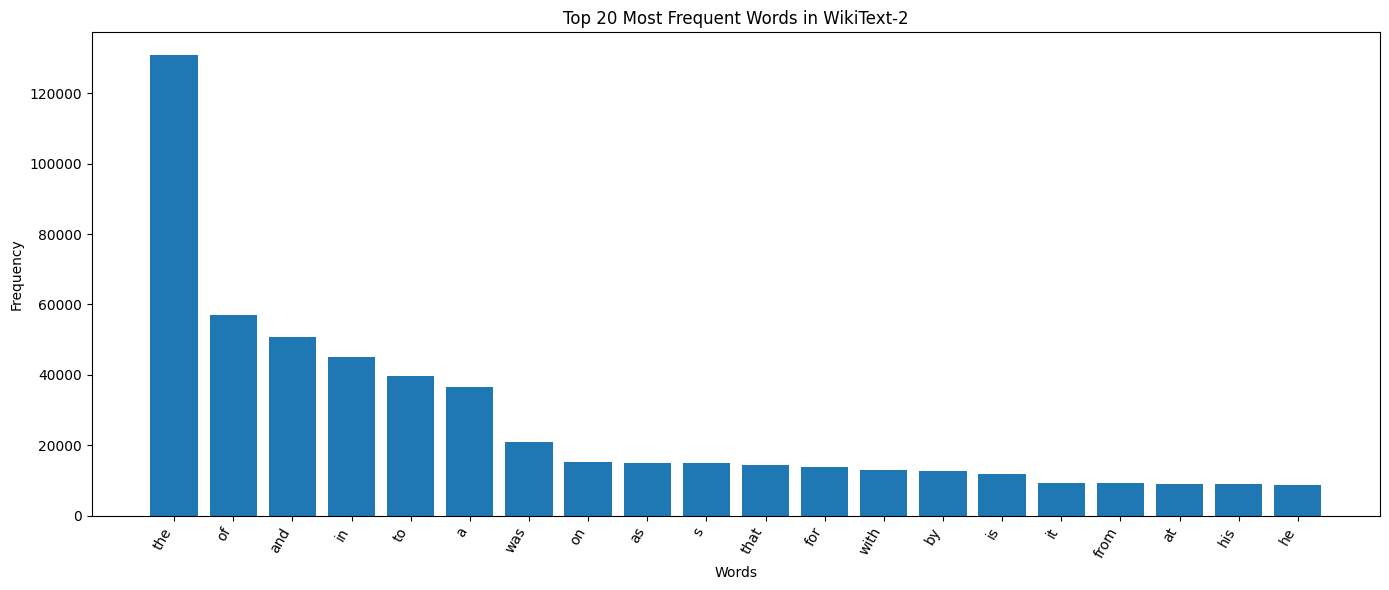

In [20]:
import matplotlib.pyplot as plt


words = [word for word, count in top_20_words]
frequencies = [count for word, count in top_20_words]


plt.figure(figsize=(14, 6))

plt.bar(words, frequencies)

plt.title("Top 20 Most Frequent Words in WikiText-2")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=60, ha="right")
plt.tight_layout()

plt.show()

In [21]:
print("UNIGRAM FREQUENCY ANALYSIS SUMMARY")
print("----------------------------------")

print("Total word tokens:", total_tokens)
print("Unique words:", unique_words)

print("\nTop 20 Words:")
display(frequency_df)

print("\nFive Unigram Probabilities:")
display(probability_df)

UNIGRAM FREQUENCY ANALYSIS SUMMARY
----------------------------------
Total word tokens: 1750947
Unique words: 65869

Top 20 Words:


,Word,Frequency
0,the,130771
1,of,57032
2,and,50738
3,in,45018
4,to,39522
5,a,36567
6,was,21008
7,on,15141
8,as,15058
9,s,14982



Five Unigram Probabilities:


,Word,Frequency,Total Tokens,Unigram Probability
0,the,130771,1750947,0.074686
1,of,57032,1750947,0.032572
2,and,50738,1750947,0.028977
3,in,45018,1750947,0.025711
4,to,39522,1750947,0.022572
